# Sandbox v2: cohort variants and processing versions, cross-sectional analyses

Reads the manuscript inputs and the rerun outputs; writes only to `sandbox/`. The last cell confirms the manuscript files are unchanged.

| cohort | definition |
|---|---|
| A0_record | cohort of record (36 / 12 / 12) |
| A1_no010 | A0 without sub-010 |
| A2_no010_hemi | A1, Hemi patients only (resection type from `marlene_lmm.py` SURG) |
| A3_prisma | A0, keeping subjects whose selected session was on the Prisma |

| version | processing |
|---|---|
| P0_record | the manuscript inputs |
| P1_nosmooth | rerun: no smoothing, word ROIs on −cope13 |
| P2_nosmooth_c20 | rerun: no smoothing, word ROIs on cope 20 (Words − Face) |

Removals filter the existing ComBat-harmonized values; the rerun versions were refit with the record's ComBat on the record's fit set (rerun_harmonize.py, checked against the record).
Stats: `D_liu/verified/05_stats_harmony.py`, unchanged, once per cohort and version (cached in `sandbox/<name>/`).
Not in this notebook: bambi evidence ratios, Tables 2 and 4, TFCE, peak location and WTA for the rerun versions.

Kernel: fmri. Run top to bottom.


## 1 · Config

In [1]:
# ─── Config ──────────────────────────────────────────────────────────────────
# Reads the manuscript inputs and writes only to sandbox/. The manuscript files
# are hashed here and again in the last cell, so any write to them is caught.
import sys, json, time, hashlib, contextlib, importlib.util
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

sys.dont_write_bytecode = True   # loading the stats script must not write __pycache__ into the repo

T_START = time.time()
REPO    = Path('/user_data/csimmon2/git_repos/sym_pt')
SANDBOX = REPO / 'sandbox'
SANDBOX.mkdir(exist_ok=True)

STATS_SCRIPT = REPO / 'D_liu' / 'verified' / '05_stats_harmony.py'
UNIVAR_SQRT  = REPO / 'D_liu' / 'univariate_v1_harmonized_sqrt.csv'
RSA_HARM     = REPO / 'D_liu' / 'rsa_v1_harmonized.csv'
SCANNER_CSV  = REPO / 'F_harmonization' / 'sub_info_scanner.csv'
RSM_CSV      = REPO / 'H_RosenkeRSM' / 'otc_rsm_persubject.csv'

# manuscript stats: read for the A0 check only
STATS_RECORD = REPO / 'D_liu' / 'stats_results_harmonized_corrected.csv'
STATS_PTPT4  = REPO / 'D_liu' / 'stats_results_harmonized_corrected_ptpt4.csv'  # compared if present
GUARDED = [STATS_RECORD, STATS_PTPT4, REPO / 'D_liu' / 'tfce_clusters.csv',
           UNIVAR_SQRT, RSA_HARM, RSM_CSV, SCANNER_CSV, STATS_SCRIPT]

# cohort of record: EXCLUDE / EXCLUDE_SES as in 05_stats_harmony.py and final_figures cell 2
EXCLUDE_RECORD = ['sub-017', 'sub-091', 'sub-095', 'sub-096', 'sub-027', 'sub-084']
EXCLUDE_SES    = [('sub-108', 2)]

# resection type, copied from marlene_lmm.py (SURG, line 71 on). sub-091 falls to the age cap.
SURG = {
    'sub-077': 'Hemi', 'sub-004': 'OTC',  'sub-075': 'OTC',  'sub-074': 'Hemi',
    'sub-008': 'Hemi', 'sub-098': 'Hemi', 'sub-079': 'OTC',  'sub-039': 'OTC',
    'sub-109': 'Hemi', 'sub-089': 'OTC',  'sub-101': 'Hemi', 'sub-005': 'OTC',
    'sub-091': 'Hemi', 'sub-099': 'Hemi', 'sub-069': 'Hemi', 'sub-044': 'OTC',
    'sub-010': 'Hemi', 'sub-021': 'OTC',  'sub-090': 'Hemi', 'sub-076': 'OTC',
    'sub-108': 'Hemi', 'sub-066': 'Hemi', 'sub-092': 'Hemi', 'sub-082': 'OTC',
    'sub-078': 'OTC',
}

FORCE = False   # True reruns the stats even when a cached run with identical inputs exists


def md5(p):
    p = Path(p)
    return hashlib.md5(p.read_bytes()).hexdigest() if p.exists() else None


HASH_BEFORE = {str(p): md5(p) for p in GUARDED}
for p in [STATS_SCRIPT, UNIVAR_SQRT, RSA_HARM, SCANNER_CSV, RSM_CSV, STATS_RECORD]:
    print(('ok       ' if p.exists() else 'MISSING  ') + str(p))

ok       /user_data/csimmon2/git_repos/sym_pt/D_liu/verified/05_stats_harmony.py
ok       /user_data/csimmon2/git_repos/sym_pt/D_liu/univariate_v1_harmonized_sqrt.csv
ok       /user_data/csimmon2/git_repos/sym_pt/D_liu/rsa_v1_harmonized.csv
ok       /user_data/csimmon2/git_repos/sym_pt/F_harmonization/sub_info_scanner.csv
ok       /user_data/csimmon2/git_repos/sym_pt/H_RosenkeRSM/otc_rsm_persubject.csv
ok       /user_data/csimmon2/git_repos/sym_pt/D_liu/stats_results_harmonized_corrected.csv


## 2 · Cohorts

In [2]:
# ─── Cohorts ─────────────────────────────────────────────────────────────────
# Same session rule as 05_stats_harmony.py: controls first session, OTC patients
# last session, after EXCLUDE and EXCLUDE_SES. Checked in both harmonized files.
# A3 keeps a subject only if its selected session was acquired on the Prisma.

def _ses_num(s):
    return pd.to_numeric(s.astype(str).str.extract(r'(\d+)', expand=False),
                         errors='coerce')


def selected_sessions(path, exclude):
    d = pd.read_csv(path, usecols=lambda c: c in
                    {'subject_id', 'session', 'group', 'status', 'intact_hemi'})
    d = d[~d['subject_id'].isin(exclude)].copy()
    d['ses_num'] = _ses_num(d['session'])
    for s, n in EXCLUDE_SES:
        d = d[~((d['subject_id'] == s) & (d['ses_num'] == n))]
    c = d[d['status'] == 'control']
    c = c[c['ses_num'] == c.groupby('subject_id')['ses_num'].transform('min')]
    p = d[d['group'] == 'OTC']
    p = p[p['ses_num'] == p.groupby('subject_id')['ses_num'].transform('max')]
    c = c.assign(cell='control')
    p = p.assign(cell=p['intact_hemi'].map({'left': 'LH-intact', 'right': 'RH-intact'}))
    return pd.concat([c, p])[['subject_id', 'ses_num', 'cell']].drop_duplicates()


sel_u = selected_sessions(UNIVAR_SQRT, EXCLUDE_RECORD)
sel_r = selected_sessions(RSA_HARM, EXCLUDE_RECORD)
_cmp = sel_u.merge(sel_r, on=['subject_id', 'cell'], how='outer',
                   suffixes=('_univariate', '_rsa'), indicator=True)
_odd = _cmp[(_cmp['_merge'] != 'both') |
            (_cmp['ses_num_univariate'] != _cmp['ses_num_rsa'])]
if len(_odd):
    print('selected session differs between the two harmonized files:')
    print(_odd.drop(columns='_merge').to_string(index=False), '\n')

BASE = pd.concat([sel_u, sel_r]).drop_duplicates(['subject_id', 'ses_num', 'cell'])
if BASE['cell'].isna().any():
    raise ValueError('patients with no intact_hemi:\n'
                     + BASE[BASE['cell'].isna()].to_string(index=False))

_sc = pd.read_csv(SCANNER_CSV)
_sc = pd.DataFrame({'subject_id': _sc['sub'], 'ses_num': _ses_num(_sc['ses']),
                    'scanner': _sc['scanner']}).drop_duplicates(['subject_id', 'ses_num'])
BASE = BASE.merge(_sc, on=['subject_id', 'ses_num'], how='left')
BASE['surg'] = BASE['subject_id'].map(SURG)

_no_sc = BASE[BASE['scanner'].isna()]
_no_sg = BASE[(BASE['cell'] != 'control') & BASE['surg'].isna()]
if len(_no_sc) or len(_no_sg):
    raise ValueError('missing labels:\n'
                     + (f'no scanner row:\n{_no_sc.to_string(index=False)}\n' if len(_no_sc) else '')
                     + (f'no SURG entry:\n{_no_sg.to_string(index=False)}' if len(_no_sg) else ''))

_pts = BASE[BASE['cell'] != 'control']
COHORTS = {
    'A0_record':     [],
    'A1_no010':      ['sub-010'],
    'A2_no010_hemi': sorted({'sub-010'} | set(_pts.loc[_pts['surg'] != 'Hemi', 'subject_id'])),
    'A3_prisma':     sorted(BASE.loc[BASE['scanner'] != 'Prisma', 'subject_id'].unique()),
}
EXCLUDES = {k: EXCLUDE_RECORD + v for k, v in COHORTS.items()}
if 'sub-010' not in set(BASE['subject_id']):
    print('NOTE: sub-010 is not in the cohort of record, so A1 equals A0')

_rows = []
for k, extra in COHORTS.items():
    n = BASE[~BASE['subject_id'].isin(extra)].drop_duplicates('subject_id')['cell'].value_counts()
    _rows.append({'cohort': k, 'controls': n.get('control', 0),
                  'LH-intact': n.get('LH-intact', 0), 'RH-intact': n.get('RH-intact', 0),
                  'dropped beyond the record': len(extra)})
COHORT_N = pd.DataFrame(_rows).set_index('cohort')
print(COHORT_N.to_string())
_n0 = COHORT_N.loc['A0_record']
if (_n0['controls'], _n0['LH-intact'], _n0['RH-intact']) != (36, 12, 12):
    print('\nWARNING: A0 is not 36 / 12 / 12')
for k, extra in COHORTS.items():
    if extra:
        print(f'\n{k} drops: ' + ', '.join(extra))

               controls  LH-intact  RH-intact  dropped beyond the record
cohort                                                                  
A0_record            36         12         12                          0
A1_no010             36         12         11                          1
A2_no010_hemi        36          6          6                         12
A3_prisma            13          8          9                         30

A1_no010 drops: sub-010

A2_no010_hemi drops: sub-004, sub-005, sub-010, sub-021, sub-039, sub-044, sub-075, sub-076, sub-078, sub-079, sub-082, sub-089

A3_prisma drops: sub-001, sub-004, sub-005, sub-008, sub-010, sub-016, sub-018, sub-021, sub-022, sub-023, sub-025, sub-026, sub-028, sub-029, sub-031, sub-034, sub-035, sub-036, sub-037, sub-039, sub-040, sub-041, sub-043, sub-044, sub-052, sub-054, sub-058, sub-062, sub-064, sub-065


## 3 · Stats per cohort

In [3]:
# ─── Stats: 05_stats_harmony.py, unchanged, once per cohort ──────────────────
# The script is loaded fresh for each cohort, so its RNG restarts at seed 42
# and A0 should reproduce the manuscript stats file exactly. Only its exclusion
# lists and output paths are replaced. Output and log go to sandbox/<cohort>/;
# a cached run is reused when the exclusions, script and inputs are unchanged.

def run_stats(name, exclude):
    out = SANDBOX / name
    out.mkdir(exist_ok=True)
    res, meta_f, log_f = out / 'stats_results.csv', out / 'meta.json', out / 'stats_log.txt'
    meta = json.loads(json.dumps({
        'exclude': sorted(exclude), 'exclude_ses': EXCLUDE_SES,
        'script_md5': md5(STATS_SCRIPT), 'univar_md5': md5(UNIVAR_SQRT),
        'rsa_md5': md5(RSA_HARM)}))
    if (not FORCE and res.exists() and meta_f.exists()
            and json.loads(meta_f.read_text()) == meta):
        print(f'{name}: cached ({res})')
        return pd.read_csv(res)

    spec = importlib.util.spec_from_file_location(f'stats05_{name}', STATS_SCRIPT)
    mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mod)                     # fresh module, fresh RNG
    mod.EXCLUDE, mod.EXCLUDE_SES = list(exclude), list(EXCLUDE_SES)
    mod.OUT_RESULTS, mod.OUT_TFCE = res, out / 'tfce_clusters.csv'

    argv, t0 = sys.argv, time.time()
    sys.argv = [str(STATS_SCRIPT)]                   # the kernel's own argv would break argparse
    try:
        with open(log_f, 'w') as log, contextlib.redirect_stdout(log), \
                contextlib.redirect_stderr(log):
            mod.main()
    except Exception:
        print(f'{name}: FAILED - last lines of {log_f}:')
        print(''.join(open(log_f).readlines()[-15:]))
        raise
    finally:
        sys.argv = argv
    meta_f.write_text(json.dumps(meta, indent=1))
    print(f'{name}: {time.time() - t0:.0f} s')
    return pd.read_csv(res)


STATS = {k: run_stats(k, v) for k, v in EXCLUDES.items()}

A0_record: cached (/user_data/csimmon2/git_repos/sym_pt/sandbox/A0_record/stats_results.csv)
A1_no010: cached (/user_data/csimmon2/git_repos/sym_pt/sandbox/A1_no010/stats_results.csv)
A2_no010_hemi: cached (/user_data/csimmon2/git_repos/sym_pt/sandbox/A2_no010_hemi/stats_results.csv)
A3_prisma: cached (/user_data/csimmon2/git_repos/sym_pt/sandbox/A3_prisma/stats_results.csv)


## 4 · Check: A0 against the manuscript stats file

In [4]:
# ─── Check: does A0 reproduce the manuscript stats file? ─────────────────────
# Compares every numeric column. Row by row when both files list the same tests
# in the same order, otherwise matched on measure/model/comparison/hemi/level.

KEYS = ['measure', 'model', 'comparison', 'hemi', 'level']


def frame_diff(new, old, tol=1e-9):
    a, b = new.copy(), old.copy()
    for d in (a, b):
        d[KEYS] = d[KEYS].fillna('').astype(str)
    if len(a) == len(b) and (a[KEYS].values == b[KEYS].values).all():
        pairs, how = (a.reset_index(drop=True), b.reset_index(drop=True)), 'row by row'
    else:
        dup = int(a.duplicated(KEYS).sum() + b.duplicated(KEYS).sum())
        m = a.merge(b, on=KEYS, how='outer', suffixes=('', '__old'), indicator=True)
        only = m[m['_merge'] != 'both']
        how = (f'by key ({len(a)} vs {len(b)} rows, {len(only)} unmatched, '
               f'{dup} duplicate keys)')
        m = m[m['_merge'] == 'both']
        pairs = (m[[c for c in m.columns if not c.endswith('__old')]],
                 m[KEYS + [c for c in m.columns if c.endswith('__old')]]
                 .rename(columns=lambda c: c.replace('__old', '')))
    x, y = pairs
    num = [c for c in y.columns if c in x.columns and c not in KEYS
           and pd.api.types.is_numeric_dtype(y[c])]
    bad = []
    for c in num:
        u = pd.to_numeric(x[c], errors='coerce').to_numpy(float)
        v = pd.to_numeric(y[c], errors='coerce').to_numpy(float)
        dd = np.abs(u - v)
        dd[np.isnan(u) & np.isnan(v)] = 0
        dd[np.isnan(dd)] = np.inf
        for i in np.where(dd > tol)[0]:
            bad.append({**{k: x[k].iloc[i] for k in KEYS}, 'column': c,
                        'record': v[i], 'sandbox': u[i]})
    return how, pd.DataFrame(bad)


for ref in [STATS_RECORD, STATS_PTPT4]:
    if not ref.exists():
        continue
    how, bad = frame_diff(STATS['A0_record'], pd.read_csv(ref))
    print(f'A0 vs {ref.name}: compared {how}')
    if bad.empty:
        print('  PASS: every value identical\n')
    else:
        print(f'  DIFFERS: {len(bad)} values in {bad[KEYS].drop_duplicates().shape[0]} rows; '
              f'max |diff| {np.nanmax(np.abs(bad.sandbox - bad.record)):.3g}')
        print(bad.head(15).to_string(index=False), '\n')

A0 vs stats_results_harmonized_corrected.csv: compared by key (274 vs 242 rows, 32 unmatched, 0 duplicate keys)
  DIFFERS: 243 values in 63 rows; max |diff| 0.0607
 measure                                 model         comparison hemi           level column   record  sandbox
geometry house_PPA_strict_LH-intact_pt_vs_ctrl  group_main_effect      MEAN_OVER_PAIRS p_perm 0.712829 0.711529
geometry house_PPA_strict_LH-intact_pt_vs_ctrl patient_vs_control           face-house p_perm 0.953305 0.959304
geometry house_PPA_strict_LH-intact_pt_vs_ctrl patient_vs_control          face-object p_perm 0.357664 0.360664
geometry house_PPA_strict_LH-intact_pt_vs_ctrl patient_vs_control            face-word p_perm 0.161384 0.168383
geometry house_PPA_strict_LH-intact_pt_vs_ctrl patient_vs_control         house-object p_perm 0.994101 0.994201
geometry house_PPA_strict_LH-intact_pt_vs_ctrl patient_vs_control           house-word p_perm 0.246775 0.243376
geometry house_PPA_strict_LH-intact_pt_vs_ctrl patie

## 5 · Whole-OTC per cohort

In [5]:
# ─── Whole-OTC: side typicality, consistency, arrangement ────────────────────
# Functions ported from whole_otc_bayes.ipynb: _zc/_corr and side typicality
# (cell 3), profile-shape permutation and consistency (cell 19), JZS BF (cell 8).
# otc_rsm_persubject.csv already holds the cohort of record, so each cohort is a
# filter of it. Fresh RNGs per cohort (seeds as in the source cells).

from scipy import integrate

_ch_all = pd.read_csv(RSM_CSV)
P6 = [c for c in _ch_all.columns if '-' in c]
assert len(P6) == 6, P6
_ch_all['set'] = np.where(
    _ch_all.group == 'control', 'ctl_' + _ch_all.hemi.str.upper(),
    np.where(_ch_all.intact_hemi == _ch_all.hemi.map({'l': 'left', 'r': 'right'}),
             'pt_' + _ch_all.hemi.str.upper(), 'drop'))
_ch_all = _ch_all[_ch_all['set'] != 'drop'].reset_index(drop=True)
SETS = ['ctl_L', 'ctl_R', 'pt_L', 'pt_R']


def _zc(M):
    return (M - M.mean(1, keepdims=True)) / M.std(1, ddof=0, keepdims=True)


def _corr(M):
    Z = _zc(M)
    return Z @ Z.T / M.shape[1]


def _shape_stat(d):
    return float(((d - d.mean()) ** 2).sum())


def bf10_jzs(x, r=0.707):
    """One-sample JZS BF10 against 0 (Rouder et al. 2009), as whole_otc_bayes cell 8."""
    x = np.asarray(x, float)
    t, n = x.mean() / (x.std(ddof=1) / np.sqrt(len(x))), len(x)
    v = n - 1

    def num(g):
        return ((1 + n * g) ** -0.5 * (1 + t ** 2 / ((1 + n * g) * v)) ** (-(v + 1) / 2)
                * (r ** 2 / 2) ** 0.5 / np.sqrt(np.pi) * g ** -1.5 * np.exp(-r ** 2 / (2 * g)))
    return integrate.quad(num, 0, np.inf)[0] / (1 + t ** 2 / v) ** (-(v + 1) / 2)


def whole_otc(exclude, nperm=10000):
    ch = _ch_all[~_ch_all['subject_id'].isin(exclude)].reset_index(drop=True)
    M = ch[P6].to_numpy(float)
    sid, st = ch['subject_id'].to_numpy(), ch['set'].to_numpy()
    SAME = sid[:, None] == sid[None, :]
    IDX = {s: np.where(st == s)[0] for s in SETS}
    C = _corr(M)

    def blk(i, j):
        b, keep = C[np.ix_(i, j)], ~SAME[np.ix_(i, j)]
        return b[keep].mean()

    typ = np.array([blk([i], IDX['ctl_' + st[i][-1]])
                    - blk([i], IDX['ctl_' + ('R' if st[i].endswith('L') else 'L')])
                    for i in range(len(M))])

    def consistency(idx):
        Z = _zc(M[idx]); Cc = Z @ Z.T / M.shape[1]
        np.fill_diagonal(Cc, np.nan)
        return np.nanmean(Cc, axis=1)

    rng_shape, rng_perm = np.random.default_rng(41), np.random.default_rng(42)

    def shape(sa, sb, paired):
        A, B = M[IDX[sa]], M[IDX[sb]]
        if paired:
            A, B = A[np.argsort(sid[IDX[sa]])], B[np.argsort(sid[IDX[sb]])]
            D = A - B
            obs = _shape_stat(D.mean(0))
            null = np.array([_shape_stat((D * rng_shape.choice([-1, 1], len(D))[:, None]).mean(0))
                             for _ in range(nperm)])
        else:
            obs = _shape_stat(A.mean(0) - B.mean(0))
            pool, na = np.vstack([A, B]), len(A)
            null = np.empty(nperm)
            for b in range(nperm):
                p = rng_shape.permutation(len(pool))
                null[b] = _shape_stat(pool[p[:na]].mean(0) - pool[p[na:]].mean(0))
        return (np.sum(null >= obs) + 1) / (nperm + 1)

    def perm1(a, b):
        obs = a.mean() - b.mean()
        pool, na, k = np.concatenate([a, b]), len(a), 0
        for _ in range(nperm):
            p = rng_perm.permutation(pool)
            k += abs(p[:na].mean() - p[na:].mean()) >= abs(obs) - 1e-12
        return (k + 1) / (nperm + 1)

    cons = {s: consistency(IDX[s]) for s in SETS}
    out = {f'n {s}': len(IDX[s]) for s in SETS}
    out.update({f'typicality {s}': typ[IDX[s]].mean() for s in SETS})
    out['typicality controls'] = typ[np.r_[IDX['ctl_L'], IDX['ctl_R']]].mean()
    out['BF10 typicality pt_L'] = bf10_jzs(typ[IDX['pt_L']])
    out['BF10 typicality pt_R'] = bf10_jzs(typ[IDX['pt_R']])
    out.update({f'consistency {s}': cons[s].mean() for s in SETS})
    out.update({f'consistency SD {s}': cons[s].std(ddof=1) for s in SETS})
    # same order as whole_otc_bayes cell 19 first, then the patient-vs-control pairs
    out['arrangement p ctl_L vs ctl_R'] = shape('ctl_L', 'ctl_R', paired=True)
    out['arrangement p pt_L vs pt_R'] = shape('pt_L', 'pt_R', paired=False)
    out['arrangement p pt_L vs ctl_L'] = shape('pt_L', 'ctl_L', paired=False)
    out['arrangement p pt_R vs ctl_R'] = shape('pt_R', 'ctl_R', paired=False)
    out['consistency p pt_L vs pt_R'] = perm1(cons['pt_L'], cons['pt_R'])
    out['consistency p pt_L vs ctl_L'] = perm1(cons['pt_L'], cons['ctl_L'])
    out['consistency p pt_R vs ctl_R'] = perm1(cons['pt_R'], cons['ctl_R'])
    return out


WOTC = pd.DataFrame({k: whole_otc(v) for k, v in EXCLUDES.items()})

# manuscript values (V3 Results) next to A0; deterministic values should match to rounding
V3_WOTC = {'typicality ctl_L': .147, 'typicality ctl_R': .050, 'typicality pt_L': .002,
           'typicality pt_R': -.008, 'typicality controls': .098,
           'BF10 typicality pt_L': .29, 'BF10 typicality pt_R': .29,
           'consistency ctl_L': .703, 'consistency ctl_R': .606,
           'consistency pt_L': .419, 'consistency pt_R': .533,
           'arrangement p ctl_L vs ctl_R': .0001, 'arrangement p pt_L vs pt_R': .969,
           'arrangement p pt_L vs ctl_L': .025, 'arrangement p pt_R vs ctl_R': .315,
           'consistency p pt_L vs pt_R': .105, 'consistency p pt_R vs ctl_R': .133}
WOTC.insert(0, 'V3', pd.Series(V3_WOTC))
_tol = {k: (.01 if ' p ' in k else .0006 if 'BF' not in k else .006) for k in V3_WOTC}
_off = [k for k in V3_WOTC if abs(WOTC.loc[k, 'A0_record'] - V3_WOTC[k]) > _tol[k]]
print('whole-OTC A0 vs V3:', 'all within rounding / permutation error' if not _off
      else 'OFF for ' + ', '.join(_off))
with pd.option_context('display.float_format', '{:.3f}'.format):
    display(WOTC)

whole-OTC A0 vs V3: all within rounding / permutation error


,V3,A0_record,A1_no010,A2_no010_hemi,A3_prisma
n ctl_L,NaN,36.000,36.000,36.000,13.000
n ctl_R,NaN,36.000,36.000,36.000,13.000
n pt_L,NaN,12.000,12.000,6.000,8.000
n pt_R,NaN,12.000,11.000,6.000,9.000
typicality ctl_L,0.147,0.147,0.147,0.147,0.077
typicality ctl_R,0.050,0.050,0.050,0.050,0.134
typicality pt_L,0.002,0.002,0.002,-0.001,-0.041
typicality pt_R,-0.008,-0.008,-0.021,-0.058,0.066
typicality controls,0.098,0.098,0.098,0.098,0.106
BF10 typicality pt_L,0.290,0.288,0.288,0.373,0.367


## 6 · Table 1 per cohort, and all reported tests

In [6]:
# ─── Table 1 per cohort, and every reported test side by side ────────────────
# Table 1 cells follow V3: regions surviving FDR for peak selectivity and voxel
# count; for between-category similarity, ROIs whose pair x group arrangement
# test is p < .05 (the rule that reproduces V3's Table 1 rows). Bayes factors
# other than whole-OTC typicality are not recomputed in this pass.

ROI_SHORT = {'word_VWFA': 'VWFA', 'face_FFA': 'FFA', 'house_PPA_strict': 'PPA',
             'object_LOC': 'LO'}
ROI_ORDER = list(ROI_SHORT)
COMP = [('ctrl L vs R',       'ctrl_LvsR',            'control_asymmetry'),
        ('LH-intact vs ctrl', 'LH-intact_pt_vs_ctrl', 'patient_vs_control'),
        ('RH-intact vs ctrl', 'RH-intact_pt_vs_ctrl', 'patient_vs_control'),
        ('pt vs pt',          'pt_LH_vs_RH',          'patient_subgroup')]
V3_TABLE1 = pd.DataFrame(
    [['PPA, LO', 'VWFA, FFA, PPA, LO', 'VWFA, FFA, PPA', '+0.098'],
     ['LO', 'LO', 'FFA', '+0.002'],
     ['—', 'PPA, LO', 'VWFA, FFA, PPA, LO', '-0.008'],
     ['—', '—', '—', '—']],
    index=[c[0] for c in COMP],
    columns=['peak selectivity', 'selective voxels', 'between-category', 'own side'])


def _sel(st, **kw):
    m = np.ones(len(st), bool)
    for k, v in kw.items():
        m &= st[k].astype(str).values == str(v)
    return st[m]


def table1(st, wo):
    rows = {}
    for lab, model, comp in COMP:
        cell = {}
        for meas, col in [('peak_selectivity', 'peak selectivity'),
                          ('selective_voxels', 'selective voxels')]:
            d = _sel(st, measure=meas, model=model, comparison=comp)
            cell[col] = ', '.join(ROI_SHORT[r] for r in ROI_ORDER
                                  if (d[d['level'] == r]['q_fdr'] < .05).any()) or '—'
        g = _sel(st, measure='geometry', comparison='omnibus')
        cell['between-category'] = ', '.join(
            ROI_SHORT[r] for r in ROI_ORDER
            if (g[g['model'] == f'{r}_{model}']['omnibus_p'] < .05).any()) or '—'
        cell['own side'] = {'ctrl L vs R': f"{wo['typicality controls']:+.3f}",
                            'LH-intact vs ctrl': f"{wo['typicality pt_L']:+.3f}",
                            'RH-intact vs ctrl': f"{wo['typicality pt_R']:+.3f}",
                            'pt vs pt': '—'}[lab]
        rows[lab] = cell
    return pd.DataFrame(rows).T[V3_TABLE1.columns]


TABLE1 = {k: table1(STATS[k], WOTC[k]) for k in STATS}
pd.concat(TABLE1, names=['cohort']).to_csv(SANDBOX / 'table1_by_cohort.csv')

print('A0 vs V3 Table 1 (cells that differ):')
_a0 = TABLE1['A0_record']
_diff = [(r, c, V3_TABLE1.loc[r, c], _a0.loc[r, c]) for r in V3_TABLE1.index
         for c in V3_TABLE1.columns
         if V3_TABLE1.loc[r, c].replace('−', '-') != _a0.loc[r, c]]
print('  none' if not _diff else
      '\n'.join(f'  {r} | {c}: V3 "{v}"  sandbox "{s}"' for r, c, v, s in _diff))

for k, t in TABLE1.items():
    print(f'\n── {k}   (controls {COHORT_N.loc[k, "controls"]}, '
          f'LH-intact {COHORT_N.loc[k, "LH-intact"]}, RH-intact {COHORT_N.loc[k, "RH-intact"]})')
    print(t.to_string())
    if k != 'A0_record':
        ch = [(r, c, _a0.loc[r, c], t.loc[r, c]) for r in t.index for c in t.columns
              if c != 'own side' and t.loc[r, c] != _a0.loc[r, c]]
        print('  changed from A0: ' + ('none' if not ch else
              '; '.join(f'{r} | {c}: "{a}" -> "{b}"' for r, c, a, b in ch)))


# ── every test the Results report, one row each, cohorts side by side ──────
def _fmt(r, stat):
    if r is None:
        return ''
    if stat == 'omnibus':
        return f"p={r['omnibus_p']:.3f}" + (' *' if r['omnibus_p'] < .05 else '')
    p = r['q_fdr'] if stat == 'q' else r['p_perm']
    lab = 'q' if stat == 'q' else 'p'
    return f"d={r['cohens_d']:+.2f} {lab}={p:.3f}" + (' *' if p < .05 else '')


def _one(st, **kw):
    d = _sel(st, **kw)
    return None if d.empty else d.iloc[0]


spec = []
for meas in ['peak_selectivity', 'selective_voxels']:
    for lab, model, comp in COMP:
        if model != 'pt_LH_vs_RH':   # no pt-vs-pt omnibus in the stats file (it comes from marlene_lmm)
            spec.append((meas, lab, 'omnibus', dict(measure=meas, model=model, comparison='omnibus'), 'omnibus'))
        spec.append((meas, lab, 'mean over ROIs', dict(measure=meas, model=model,
                     comparison='group_main_effect', level='MEAN_OVER_ROIS'), 'p'))
        for roi in ROI_ORDER:
            spec.append((meas, lab, ROI_SHORT[roi], dict(measure=meas, model=model,
                         comparison=comp, level=roi), 'q'))
for roi in ROI_ORDER:
    for lab, model, comp in COMP:
        spec.append(('geometry', lab, f'{ROI_SHORT[roi]} arrangement',
                     dict(measure='geometry', model=f'{roi}_{model}', comparison='omnibus'), 'omnibus'))
        spec.append(('geometry', lab, f'{ROI_SHORT[roi]} mean of six',
                     dict(measure='geometry', model=f'{roi}_{model}',
                          comparison='group_main_effect', level='MEAN_OVER_PAIRS'), 'p'))
        for pair in ['face-house', 'face-object', 'face-word',
                     'house-object', 'house-word', 'object-word']:
            hit = [_one(STATS[k], measure='geometry', model=f'{roi}_{model}',
                        comparison=comp, level=pair) for k in STATS]
            if any(h is not None and h['q_fdr'] < .05 for h in hit):   # pairs significant in any cohort
                spec.append(('geometry', lab, f'{ROI_SHORT[roi]} {pair}',
                             dict(measure='geometry', model=f'{roi}_{model}',
                                  comparison=comp, level=pair), 'q'))
for lab, model, comp in COMP[1:3]:
    for roi in ROI_ORDER:
        spec.append(('peak_distance', lab, ROI_SHORT[roi], dict(measure='peak_distance',
                     model=model, comparison='patient_vs_control', level=roi), 'q'))

ALL = pd.DataFrame([{'measure': m, 'comparison': lab, 'test': t,
                     **{k: _fmt(_one(STATS[k], **kw), stat) for k in STATS}}
                    for m, lab, t, kw, stat in spec])
ALL.to_csv(SANDBOX / 'all_tests_by_cohort.csv', index=False)
print(f'\nAll reported tests by cohort ({len(ALL)} rows; * = p or q < .05; '
      f'saved to {SANDBOX / "all_tests_by_cohort.csv"}):')
with pd.option_context('display.max_rows', 500, 'display.max_colwidth', 40):
    display(ALL)

A0 vs V3 Table 1 (cells that differ):
  pt vs pt | between-category: V3 "—"  sandbox "FFA"

── A0_record   (controls 36, LH-intact 12, RH-intact 12)
                  peak selectivity    selective voxels    between-category own side
ctrl L vs R                PPA, LO  VWFA, FFA, PPA, LO      VWFA, FFA, PPA   +0.098
LH-intact vs ctrl               LO                  LO                 FFA   +0.002
RH-intact vs ctrl                —             PPA, LO  VWFA, FFA, PPA, LO   -0.008
pt vs pt                         —                   —                 FFA        —

── A1_no010   (controls 36, LH-intact 12, RH-intact 11)
                  peak selectivity    selective voxels    between-category own side
ctrl L vs R          VWFA, PPA, LO  VWFA, FFA, PPA, LO      VWFA, FFA, PPA   +0.098
LH-intact vs ctrl               LO                  LO                 FFA   +0.002
RH-intact vs ctrl                —             PPA, LO  VWFA, FFA, PPA, LO   -0.021
pt vs pt                         —    

,measure,comparison,test,A0_record,A1_no010,A2_no010_hemi,A3_prisma
0,peak_selectivity,ctrl L vs R,omnibus,p=0.011 *,p=0.011 *,p=0.011 *,p=0.166
1,peak_selectivity,ctrl L vs R,mean over ROIs,d=-0.13 p=0.433,d=-0.13 p=0.427,d=-0.13 p=0.433,d=-0.40 p=0.172
2,peak_selectivity,ctrl L vs R,VWFA,d=+0.36 q=0.050,d=+0.36 q=0.049 *,d=+0.36 q=0.053,d=+0.04 q=0.904
3,peak_selectivity,ctrl L vs R,FFA,d=-0.30 q=0.075,d=-0.30 q=0.081,d=-0.30 q=0.077,d=-0.48 q=0.217
4,peak_selectivity,ctrl L vs R,PPA,d=-0.42 q=0.032 *,d=-0.42 q=0.035 *,d=-0.42 q=0.035 *,d=-0.40 q=0.240
5,peak_selectivity,ctrl L vs R,LO,d=+0.42 q=0.032 *,d=+0.42 q=0.035 *,d=+0.42 q=0.035 *,d=+0.49 q=0.217
6,peak_selectivity,LH-intact vs ctrl,omnibus,p=0.104,p=0.104,p=0.100,p=0.074
7,peak_selectivity,LH-intact vs ctrl,mean over ROIs,d=-0.71 p=0.040 *,d=-0.71 p=0.041 *,d=-1.30 p=0.006 *,d=-0.96 p=0.048 *
8,peak_selectivity,LH-intact vs ctrl,VWFA,d=-0.20 q=0.546,d=-0.20 q=0.544,d=-0.75 q=0.130,d=-0.13 q=0.791
9,peak_selectivity,LH-intact vs ctrl,FFA,d=-0.38 q=0.354,d=-0.38 q=0.356,d=-0.64 q=0.153,d=-0.67 q=0.198


## 7 · Are the two patient groups more alike than the two control hemispheres?

In [7]:
# ─── Are the two patient groups more alike than the two control hemispheres? ─
# Port of final_figures cell 47, run once per cohort. Whole-OTC profiles.
#   patients: every LH-intact x RH-intact pair
#   controls: every control-left x control-right pair, same-subject pairs dropped
#   test: patient/control label shuffled within each side (10,000, two-tailed)
# Positive and significant = the patient groups resemble each other more than the
# control hemispheres do. V3: +0.508 vs +0.556, difference -0.048, p = .552.
# Needs RSM_CSV and EXCLUDES from cells 1 and 2.

def agreement(exclude, nperm=10000):
    ch = pd.read_csv(RSM_CSV)
    ch = ch[~ch['subject_id'].isin(exclude)]
    pairs = [c for c in ch.columns if '-' in c]
    L, R = ch[ch.hemi == 'l'], ch[ch.hemi == 'r']
    s = {'ctl_L': L[L.group == 'control'], 'ctl_R': R[R.group == 'control'],
         'pt_L': L[(L.group == 'OTC') & (L.intact_hemi == 'left')],
         'pt_R': R[(R.group == 'OTC') & (R.intact_hemi == 'right')]}

    def z(M):
        M = np.asarray(M, float)
        return (M - M.mean(1, keepdims=True)) / M.std(1, ddof=0, keepdims=True)

    left, right = pd.concat([s['ctl_L'], s['pt_L']]), pd.concat([s['ctl_R'], s['pt_R']])
    X = z(left[pairs].to_numpy()) @ z(right[pairs].to_numpy()).T / len(pairs)
    same = left['subject_id'].to_numpy()[:, None] == right['subject_id'].to_numpy()[None, :]
    nCL, nPL, nPR = len(s['ctl_L']), len(s['pt_L']), len(s['pt_R'])

    def cross(li, ri):
        keep = ~same[np.ix_(li, ri)]
        return X[np.ix_(li, ri)][keep].mean()

    pt = cross(np.arange(nCL, nCL + nPL), np.arange(len(s['ctl_R']), len(right)))
    ctl = cross(np.arange(nCL), np.arange(len(s['ctl_R'])))
    rng, null = np.random.default_rng(42), np.empty(nperm)
    for b in range(nperm):
        iL, iR = rng.permutation(len(left)), rng.permutation(len(right))
        null[b] = cross(iL[:nPL], iR[:nPR]) - cross(iL[nPL:], iR[nPR:])
    p = (np.sum(np.abs(null) >= abs(pt - ctl) - 1e-12) + 1) / (nperm + 1)
    return {'controls (L, R)': f"{len(s['ctl_L'])}, {len(s['ctl_R'])}",
            'patients (LH, RH)': f'{nPL}, {nPR}',
            'patient groups agree': round(pt, 3), 'control hemispheres agree': round(ctl, 3),
            'difference': round(pt - ctl, 3), 'p': round(p, 4)}


AGREE = pd.DataFrame({k: agreement(v) for k, v in EXCLUDES.items()}).T
AGREE.loc['V3'] = ['36, 36', '12, 12', .508, .556, -.048, .552]
AGREE.to_csv(SANDBOX / 'agreement_by_cohort.csv')
display(AGREE)

,"controls (L, R)","patients (LH, RH)",patient groups agree,control hemispheres agree,difference,p
A0_record,"36, 36","12, 12",0.508,0.556,-0.048,0.5521
A1_no010,"36, 36","12, 11",0.515,0.556,-0.041,0.6197
A2_no010_hemi,"36, 36","6, 6",0.466,0.556,-0.09,0.4266
A3_prisma,"13, 13","8, 9",0.477,0.618,-0.141,0.2372
V3,"36, 36","12, 12",0.508,0.556,-0.048,0.552


## 8 · Left-versus-right resemblance on a single axis

whole-OTC typicality, A0 vs V3: match


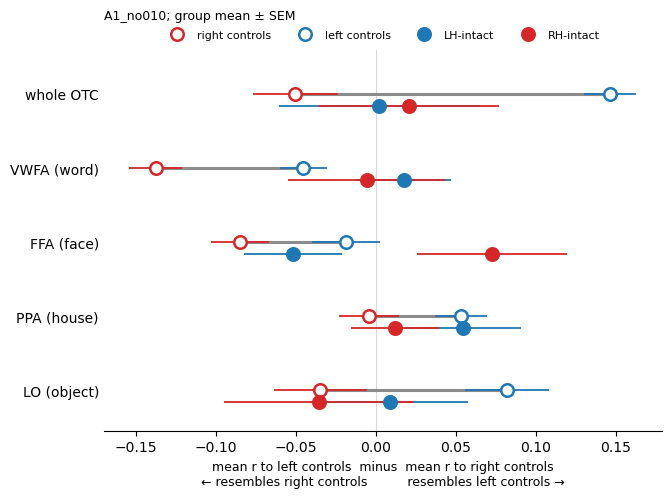

,region,group,n,left minus right,SEM,"position (right ctrl = 0, left ctrl = 1)"
0,whole OTC,right controls,36,-0.050,+0.027,+0.000
1,whole OTC,left controls,36,+0.147,+0.016,+1.000
2,whole OTC,LH-intact,12,+0.002,+0.063,+0.266
3,whole OTC,RH-intact,11,+0.021,+0.056,+0.361
4,VWFA (word),right controls,36,-0.138,+0.017,+0.000
5,VWFA (word),left controls,36,-0.045,+0.015,+1.000
6,VWFA (word),LH-intact,12,+0.017,+0.030,+1.681
7,VWFA (word),RH-intact,11,-0.006,+0.049,+1.429
8,FFA (face),right controls,36,-0.085,+0.018,+0.000
9,FFA (face),left controls,36,-0.018,+0.021,+1.000


In [8]:
# ─── Left-versus-right resemblance on a single axis: whole OTC and each ROI ──
# Per hemisphere: mean r to left-control hemispheres minus mean r to right-control
# hemispheres, over its six between-category similarities, self and same-subject
# pairs excluded (the whole-OTC side-typicality computation, cell 5). Positive =
# resembles left controls more; negative = right controls. One row per region:
# right controls and left controls mark the two ends, patients fall along the line.
# Whole OTC from otc_rsm_persubject.csv; each ROI from its 7 mm sphere in
# rsa_v1_harmonized.csv, same sessions as the stats. Needs cells 1, 2 and 5.
# Writes two files to sandbox/ and nothing else.
import matplotlib.pyplot as plt

COHORT = 'A1_no010'                      # any key of COHORTS
ROWS   = [('whole OTC', None), ('VWFA (word)', 'word_VWFA'), ('FFA (face)', 'face_FFA'),
          ('PPA (house)', 'house_PPA_strict'), ('LO (object)', 'object_LOC')]
PAIRS6 = ['face-house', 'face-object', 'face-word', 'house-object', 'house-word', 'object-word']
GROUPS = [('ctl_R', 'right controls'), ('ctl_L', 'left controls'),
          ('pt_L', 'LH-intact'), ('pt_R', 'RH-intact')]
BLUE, RED = '#1f77b4', '#d62728'          # cell_typicality.py convention: open = control, filled = patient
STYLE = {'ctl_L': (BLUE, 'white'), 'ctl_R': (RED, 'white'), 'pt_L': (BLUE, BLUE), 'pt_R': (RED, RED)}
DY = {'ctl_R': 0, 'ctl_L': 0, 'pt_L': -.16, 'pt_R': -.16}   # patients drawn just under their row's line

_rsa = pd.read_csv(RSA_HARM)
_rsa['ses_num'] = _ses_num(_rsa['session'])
_rsa = _rsa.merge(sel_r, on=['subject_id', 'ses_num'])        # RSA's selected sessions (cell 2)
_rsa = _rsa[(_rsa['cell'] == 'control') |
            ((_rsa['cell'] == 'LH-intact') & (_rsa['hemi'] == 'l')) |
            ((_rsa['cell'] == 'RH-intact') & (_rsa['hemi'] == 'r'))].copy()
_rsa['set'] = np.where(_rsa['cell'] == 'control', 'ctl_' + _rsa['hemi'].str.upper(),
                       np.where(_rsa['cell'] == 'LH-intact', 'pt_L', 'pt_R'))


def roi_profiles(roi):
    w = (_rsa[_rsa['category'] == roi]
         .pivot_table(index=['subject_id', 'set'], columns='pair', values='fisher_r', aggfunc='first'))
    return w[PAIRS6].dropna().reset_index()


def left_minus_right(frame, cols, exclude):
    f = frame[~frame['subject_id'].isin(exclude)].reset_index(drop=True)
    M = f[cols].to_numpy(float)
    Z = (M - M.mean(1, keepdims=True)) / M.std(1, ddof=0, keepdims=True)
    C = Z @ Z.T / M.shape[1]
    sid, st = f['subject_id'].to_numpy(), f['set'].to_numpy().astype(str)
    same = sid[:, None] == sid[None, :]

    def mean_to(i, s):
        return C[i, np.where((st == s) & ~same[i])[0]].mean()

    f['lr'] = [mean_to(i, 'ctl_L') - mean_to(i, 'ctl_R') for i in range(len(f))]
    return f


# check: at the cohort of record, whole OTC must reproduce V3's typicality
# (left controls +0.147, right controls +0.050, LH-intact +0.002, RH-intact -0.008;
# typicality is lr for left-side sets and -lr for right-side sets)
_v = left_minus_right(_ch_all, P6, EXCLUDES['A0_record']).groupby('set')['lr'].mean()
_t = {'ctl_L': .147, 'ctl_R': -.050, 'pt_L': .002, 'pt_R': .008}
print('whole-OTC typicality, A0 vs V3:',
      'match' if all(abs(_v[k] - t) < .0006 for k, t in _t.items())
      else 'OFF ' + str(_v.round(3).to_dict()))

fig, ax = plt.subplots(figsize=(7.2, 0.75 * len(ROWS) + 1.2))
out = []
for r, (title, roi) in enumerate(ROWS):
    frame, cols = (_ch_all, P6) if roi is None else (roi_profiles(roi), PAIRS6)
    f = left_minus_right(frame, cols, EXCLUDES[COHORT])
    m = {s: f.loc[f['set'] == s, 'lr'] for s, _ in GROUPS}
    y = -r
    ax.plot([m['ctl_R'].mean(), m['ctl_L'].mean()], [y, y], color='0.55', lw=2.2,
            solid_capstyle='round', zorder=1)                 # right controls to left controls
    for s, lab in GROUPS:
        v = m[s]
        edge, face = STYLE[s]
        ax.errorbar(v.mean(), y + DY[s], xerr=v.std(ddof=1) / np.sqrt(len(v)), fmt='o', ms=9,
                    mfc=face, mec=edge, mew=1.8, ecolor=edge, elinewidth=1.3, capsize=0, zorder=3,
                    label=f'{lab}' if r == 0 else None)
    span = m['ctl_L'].mean() - m['ctl_R'].mean()
    for s, lab in GROUPS:
        out.append({'region': title, 'group': lab, 'n': len(m[s]), 'left minus right': m[s].mean(),
                    'SEM': m[s].std(ddof=1) / np.sqrt(len(m[s])),
                    'position (right ctrl = 0, left ctrl = 1)':
                        (m[s].mean() - m['ctl_R'].mean()) / span if span else np.nan})
ax.axvline(0, color='0.85', lw=.8, zorder=0)
ax.set_yticks([-r for r in range(len(ROWS))])
ax.set_yticklabels([t for t, _ in ROWS])
ax.set_ylim(-len(ROWS) + .45, .6)
ax.set_xlabel('mean r to left controls  minus  mean r to right controls\n'
              '\u2190 resembles right controls          resembles left controls \u2192', fontsize=9)
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.tick_params(axis='y', length=0)
ax.legend(fontsize=8, frameon=False, ncol=4, loc='lower center', bbox_to_anchor=(.5, 1.0))
ax.set_title(f'{COHORT}; group mean \u00b1 SEM', fontsize=9, loc='left', pad=22)
fig.savefig(SANDBOX / f'typicality_line_{COHORT}.png', dpi=300, bbox_inches='tight', facecolor='white')
fig.savefig(SANDBOX / f'typicality_line_{COHORT}.pdf', bbox_inches='tight')
plt.show()

TYP_LINE = pd.DataFrame(out)
with pd.option_context('display.float_format', '{:+.3f}'.format):
    display(TYP_LINE)

## 9 · Processing versions

In [9]:
# ─── Processing versions: record vs no smoothing vs no smoothing + new word contrast ───
# P0 record       : the manuscript inputs (cells 3 and 5)
# P1 nosmooth     : rerun, no smoothing, word ROIs on -cope13   (rerun_harmonize new13)
# P2 nosmooth_c20 : rerun, no smoothing, word ROIs on cope 20   (rerun_harmonize new20)
# Whole OTC uses copes 6-9 only, so P1 and P2 share one whole-OTC file (no smoothing).
# Stats: 05_stats_harmony.py unchanged, given each version's files with --univar/--rsa.
# Peak location (record MNI peaks) and WTA are not rerun, so they are left out here.
# Needs cells 1-6. Writes only to sandbox/.

HARM = REPO / 'sandbox' / 'rerun_harmonize'
XTR  = REPO / 'sandbox' / 'rerun_extract'
VERSIONS = {
    'P0_record':       (UNIVAR_SQRT, RSA_HARM, RSM_CSV),
    'P1_nosmooth':     (HARM / 'new13' / 'univariate_v1_harmonized_sqrt.csv',
                        HARM / 'new13' / 'rsa_v1_harmonized.csv', XTR / 'wotc_new' / 'otc_rsm_persubject.csv'),
    'P2_nosmooth_c20': (HARM / 'new20' / 'univariate_v1_harmonized_sqrt.csv',
                        HARM / 'new20' / 'rsa_v1_harmonized.csv', XTR / 'wotc_new' / 'otc_rsm_persubject.csv'),
}
COHORTS_V = ['A0_record', 'A1_no010']
_missing = [str(p) for v in VERSIONS.values() for p in v if not Path(p).exists()]
if _missing:
    raise FileNotFoundError('run rerun_extract / rerun_harmonize first; missing:\n' + '\n'.join(_missing))

# check: whole OTC re-run on the record tree must reproduce the record file
_a = pd.read_csv(XTR / 'wotc_rec' / 'otc_rsm_persubject.csv')
_b = pd.read_csv(RSM_CSV)
_m = _a.merge(_b, on=['subject_id', 'hemi'], suffixes=('', '_r'))
_d = max(float((_m[c] - _m[c + '_r']).abs().max()) for c in P6)
print(f'whole-OTC record check: {len(_a)} rows here, {len(_b)} in the record, {len(_m)} matched, '
      f'max |diff| {_d:.2e} -> {"PASS" if len(_a) == len(_b) == len(_m) and _d < 1e-9 else "DIFFERS"}')
_exc = REPO / 'sandbox' / 'rerun' / 'exceptions.txt'
if _exc.exists():
    print('rerun exceptions (one run fewer than the record):')
    for _l in _exc.read_text().splitlines():
        print('  ' + _l.split(':')[0])


def run_stats_v(version, cohort, univar, rsa):
    name = f'{version}__{cohort}'
    out = SANDBOX / name
    out.mkdir(exist_ok=True)
    res, meta_f, log_f = out / 'stats_results.csv', out / 'meta.json', out / 'stats_log.txt'
    meta = json.loads(json.dumps({'exclude': sorted(EXCLUDES[cohort]), 'exclude_ses': EXCLUDE_SES,
                                  'script_md5': md5(STATS_SCRIPT), 'univar_md5': md5(univar), 'rsa_md5': md5(rsa)}))
    if not FORCE and res.exists() and meta_f.exists() and json.loads(meta_f.read_text()) == meta:
        print(f'{name}: cached'); return pd.read_csv(res)
    spec = importlib.util.spec_from_file_location(f'stats05_{name}', STATS_SCRIPT)
    mod = importlib.util.module_from_spec(spec); spec.loader.exec_module(mod)
    mod.EXCLUDE, mod.EXCLUDE_SES = list(EXCLUDES[cohort]), list(EXCLUDE_SES)
    mod.OUT_RESULTS, mod.OUT_TFCE = res, out / 'tfce_clusters.csv'
    argv, t0 = sys.argv, time.time()
    sys.argv = [str(STATS_SCRIPT), '--univar', str(univar), '--rsa', str(rsa)]
    try:
        with open(log_f, 'w') as log, contextlib.redirect_stdout(log), contextlib.redirect_stderr(log):
            mod.main()
    finally:
        sys.argv = argv
    meta_f.write_text(json.dumps(meta, indent=1))
    print(f'{name}: {time.time() - t0:.0f} s')
    return pd.read_csv(res)


def wotc_v(csv, exclude):
    """Cell 5's whole_otc() on another per-subject file (same set-up as cell 5)."""
    global _ch_all
    keep = _ch_all
    d = pd.read_csv(csv)
    assert [c for c in d.columns if '-' in c] == P6, 'pair columns differ from the record file'
    d['set'] = np.where(d.group == 'control', 'ctl_' + d.hemi.str.upper(),
                        np.where(d.intact_hemi == d.hemi.map({'l': 'left', 'r': 'right'}),
                                 'pt_' + d.hemi.str.upper(), 'drop'))
    _ch_all = d[d['set'] != 'drop'].reset_index(drop=True)
    try:
        return pd.Series(whole_otc(exclude))
    finally:
        _ch_all = keep


VSTATS, VWOTC = {}, {}
for version, (uni, rsa, rsm) in VERSIONS.items():
    for cohort in COHORTS_V:
        VSTATS[version, cohort] = (STATS[cohort] if version == 'P0_record'
                                   else run_stats_v(version, cohort, uni, rsa))
        VWOTC[version, cohort] = (WOTC[cohort] if version == 'P0_record'
                                  else wotc_v(rsm, EXCLUDES[cohort]))


def key_claims(st, wo):
    g = _sel(st, measure='geometry', comparison='omnibus', model='face_FFA_pt_LH_vs_RH')
    return {
        'control hemispheres differ, whole OTC (p)':   wo['arrangement p ctl_L vs ctl_R'],
        'patient groups differ, whole OTC (p)':        wo['arrangement p pt_L vs pt_R'],
        'the one exception, FFA arrangement (p)':      float(g['omnibus_p'].iloc[0]) if len(g) else np.nan,
        'side typicality, controls':                   wo['typicality controls'],
        'side typicality, LH-intact':                  wo['typicality pt_L'],
        'side typicality, RH-intact':                  wo['typicality pt_R'],
        'consistency, LH-intact / RH-intact':          f"{wo['consistency pt_L']:.3f} / {wo['consistency pt_R']:.3f}",
    }


KEY = pd.DataFrame({f'{v} | {c}': key_claims(VSTATS[v, c], VWOTC[v, c]) for v, c in VSTATS})
KEY.to_csv(SANDBOX / 'versions_key_claims.csv')
print('\nKey claims by version and cohort:')
with pd.option_context('display.float_format', '{:.3f}'.format, 'display.max_colwidth', 30):
    display(KEY)

VTABLE1 = {k: table1(VSTATS[k], VWOTC[k]) for k in VSTATS}
pd.concat({f'{v} | {c}': t for (v, c), t in VTABLE1.items()}, names=['version | cohort']).to_csv(
    SANDBOX / 'versions_table1.csv')
for (v, c), t in VTABLE1.items():
    print(f'\n── {v} | {c}')
    print(t.to_string())
    if v != 'P0_record':
        ref = VTABLE1['P0_record', c]
        ch = [f'{r} | {col}: "{ref.loc[r, col]}" -> "{t.loc[r, col]}"' for r in t.index for col in t.columns
              if col != 'own side' and t.loc[r, col] != ref.loc[r, col]]
        print('  changed from the record: ' + ('none' if not ch else '; '.join(ch)))
print(f'\nsaved: {SANDBOX / "versions_key_claims.csv"}, {SANDBOX / "versions_table1.csv"}')

whole-OTC record check: 96 rows here, 96 in the record, 96 matched, max |diff| 0.00e+00 -> PASS
rerun exceptions (one run fewer than the record):
  sub-004 ses-06
  sub-087 ses-01
  sub-095 ses-01
  sub-097 ses-01
P1_nosmooth__A0_record: 103 s
P1_nosmooth__A1_no010: 99 s
P2_nosmooth_c20__A0_record: 100 s
P2_nosmooth_c20__A1_no010: 100 s

Key claims by version and cohort:


,P0_record | A0_record,P0_record | A1_no010,P1_nosmooth | A0_record,P1_nosmooth | A1_no010,P2_nosmooth_c20 | A0_record,P2_nosmooth_c20 | A1_no010
"control hemispheres differ, whole OTC (p)",0.000,0.000,0.000,0.000,0.000,0.000
"patient groups differ, whole OTC (p)",0.971,0.996,1.000,0.998,1.000,0.998
"the one exception, FFA arrangement (p)",0.006,0.020,0.881,0.789,0.881,0.790
"side typicality, controls",0.098,0.098,0.098,0.098,0.098,0.098
"side typicality, LH-intact",0.002,0.002,-0.036,-0.036,-0.036,-0.036
"side typicality, RH-intact",-0.008,-0.021,0.009,-0.015,0.009,-0.015
"consistency, LH-intact / RH-intact",0.419 / 0.533,0.419 / 0.547,0.316 / 0.380,0.316 / 0.421,0.316 / 0.380,0.316 / 0.421



── P0_record | A0_record
                  peak selectivity    selective voxels    between-category own side
ctrl L vs R                PPA, LO  VWFA, FFA, PPA, LO      VWFA, FFA, PPA   +0.098
LH-intact vs ctrl               LO                  LO                 FFA   +0.002
RH-intact vs ctrl                —             PPA, LO  VWFA, FFA, PPA, LO   -0.008
pt vs pt                         —                   —                 FFA        —

── P0_record | A1_no010
                  peak selectivity    selective voxels    between-category own side
ctrl L vs R          VWFA, PPA, LO  VWFA, FFA, PPA, LO      VWFA, FFA, PPA   +0.098
LH-intact vs ctrl               LO                  LO                 FFA   +0.002
RH-intact vs ctrl                —             PPA, LO  VWFA, FFA, PPA, LO   -0.021
pt vs pt                         —                   —                 FFA        —

── P1_nosmooth | A0_record
                  peak selectivity selective voxels    between-category own side


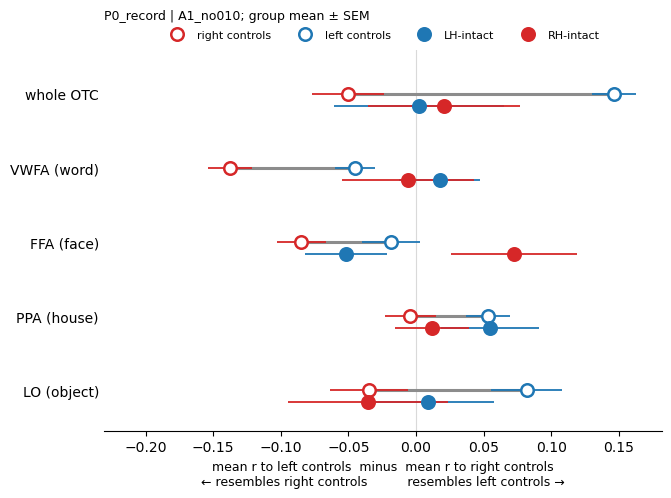

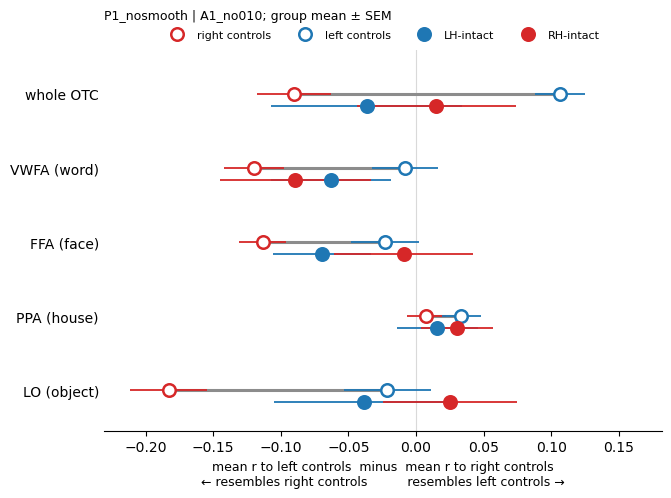

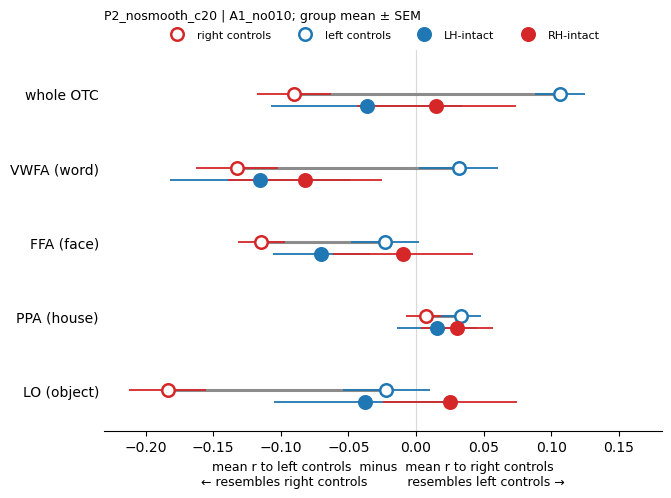

P0_record  P1_nosmooth  P2_nosmooth_c20
region      group                                                  
FFA (face)  LH-intact          -0.052       -0.070           -0.070
            RH-intact          +0.073       -0.009           -0.009
            left controls      -0.018       -0.023           -0.023
            right controls     -0.085       -0.113           -0.114
LO (object) LH-intact          +0.009       -0.038           -0.038
            RH-intact          -0.036       +0.025           +0.025
            left controls      +0.082       -0.021           -0.022
            right controls     -0.035       -0.183           -0.184
PPA (house) LH-intact          +0.055       +0.016           +0.016
            RH-intact          +0.012       +0.030           +0.030
            left controls      +0.053       +0.034           +0.033
            right controls     -0.004       +0.008           +0.007
VWFA (word) LH-intact          +0.017       -0.063           -0.116
            RH-intact          -0.006       -0.089           -0.082
            left controls      -0.045       -0.008           +0.031
            right controls     -0.138       -0.120           -0.132
whole OTC   LH-intact          +0.002       -0.036           -0.036
            RH-intact          +0.021       +0.015           +0.015
            left controls      +0.147       +0.106           +0.106
            right controls     -0.050       -0.090           -0.090

In [11]:
# ─── Single-axis figure for each processing version (cell 8 draws the record only) ───
# Same computation and layout as cell 8, with each version's RSA file and whole-OTC
# file; one figure per version, all on the same x-axis limits. Needs cells 1-9.
# Writes one figure per version to sandbox/ and nothing else.
import matplotlib.pyplot as plt

COHORT_FIG = 'A1_no010'


def version_frames(rsa_csv, rsm_csv):
    r = pd.read_csv(rsa_csv)
    r['ses_num'] = _ses_num(r['session'])
    r = r.merge(sel_r, on=['subject_id', 'ses_num'])
    r = r[(r['cell'] == 'control') | ((r['cell'] == 'LH-intact') & (r['hemi'] == 'l')) |
          ((r['cell'] == 'RH-intact') & (r['hemi'] == 'r'))].copy()
    r['set'] = np.where(r['cell'] == 'control', 'ctl_' + r['hemi'].str.upper(),
                        np.where(r['cell'] == 'LH-intact', 'pt_L', 'pt_R'))
    w = pd.read_csv(rsm_csv)
    w['set'] = np.where(w.group == 'control', 'ctl_' + w.hemi.str.upper(),
                        np.where(w.intact_hemi == w.hemi.map({'l': 'left', 'r': 'right'}),
                                 'pt_' + w.hemi.str.upper(), 'drop'))
    return r, w[w['set'] != 'drop'].reset_index(drop=True)


def region_frame(r, w, roi):
    if roi is None:
        return w, P6
    p = (r[r['category'] == roi]
         .pivot_table(index=['subject_id', 'set'], columns='pair', values='fisher_r', aggfunc='first'))
    return p[PAIRS6].dropna().reset_index(), PAIRS6


results = {}
for version, (uni, rsa, rsm) in VERSIONS.items():
    r, w = version_frames(rsa, rsm)
    rows = {}
    for title, roi in ROWS:
        f = left_minus_right(*region_frame(r, w, roi), EXCLUDES[COHORT_FIG])
        rows[title] = {s: f.loc[f['set'] == s, 'lr'] for s, _ in GROUPS}
    results[version] = rows

allv = np.concatenate([[v.mean() - v.std(ddof=1) / np.sqrt(len(v)), v.mean() + v.std(ddof=1) / np.sqrt(len(v))]
                       for rows in results.values() for m in rows.values() for v in m.values()])
pad = .05 * (allv.max() - allv.min())
xlim = (allv.min() - pad, allv.max() + pad)

table = {}
for version, rows in results.items():
    fig, ax = plt.subplots(figsize=(7.2, 0.75 * len(ROWS) + 1.2))
    for i, (title, roi) in enumerate(ROWS):
        m, y = rows[title], -i
        ax.plot([m['ctl_R'].mean(), m['ctl_L'].mean()], [y, y], color='0.55', lw=2.2,
                solid_capstyle='round', zorder=1)
        for s, lab in GROUPS:
            v = m[s]
            edge, face = STYLE[s]
            ax.errorbar(v.mean(), y + DY[s], xerr=v.std(ddof=1) / np.sqrt(len(v)), fmt='o', ms=9,
                        mfc=face, mec=edge, mew=1.8, ecolor=edge, elinewidth=1.3, capsize=0, zorder=3,
                        label=lab if i == 0 else None)
            table[title, lab, version] = v.mean()
    ax.axvline(0, color='0.85', lw=.8, zorder=0)
    ax.set_yticks([-i for i in range(len(ROWS))]); ax.set_yticklabels([t for t, _ in ROWS])
    ax.set(xlim=xlim, ylim=(-len(ROWS) + .45, .6))
    ax.set_xlabel('mean r to left controls  minus  mean r to right controls\n'
                  '\u2190 resembles right controls          resembles left controls \u2192', fontsize=9)
    ax.spines[['top', 'right', 'left']].set_visible(False); ax.tick_params(axis='y', length=0)
    ax.legend(fontsize=8, frameon=False, ncol=4, loc='lower center', bbox_to_anchor=(.5, 1.0))
    ax.set_title(f'{version} | {COHORT_FIG}; group mean \u00b1 SEM', fontsize=9, loc='left', pad=22)
    fig.savefig(SANDBOX / f'typicality_line_{COHORT_FIG}_{version}.png', dpi=300, bbox_inches='tight', facecolor='white')
    fig.savefig(SANDBOX / f'typicality_line_{COHORT_FIG}_{version}.pdf', bbox_inches='tight')
    plt.show()

LINE_V = pd.Series(table).unstack(level=-1)
LINE_V.index.names = ['region', 'group']
LINE_V = LINE_V[list(VERSIONS)]
with pd.option_context('display.float_format', '{:+.3f}'.format):
    display(LINE_V)

In [12]:
# ─── Does each group lean toward the left controls or the right controls? ────
# Uses the values from the cell above (results): for every hemisphere, how much
# more its pattern resembles left controls than right controls.
#   positive = more like left controls     negative = more like right controls
# For each region, group and version (cohort A1_no010):
#   lean     the group's average
#   p        sign-flip permutation test of "no lean" (two-sided, 10,000 flips)
#   BF10     one-sample JZS Bayes factor (r = 0.707, as in cell 5)
#   verdict  BF10 > 3: leans left / leans right;  BF10 < 1/3: leans neither way;
#            otherwise: unclear (the paper's convention)
# A new analysis, not in V3. Needs the cell above. Writes one CSV to sandbox/.

_rng_lean = np.random.default_rng(7)


def lean_test(v, nperm=10000):
    v = np.asarray(v, float)
    v = v[~np.isnan(v)]
    obs = v.mean()
    null = (_rng_lean.choice([-1, 1], size=(nperm, len(v))) * v).mean(1)
    p = (np.sum(np.abs(null) >= abs(obs) - 1e-12) + 1) / (nperm + 1)
    return obs, p, bf10_jzs(v), len(v)


def verdict(m, bf):
    if bf > 3:
        return 'leans left' if m > 0 else 'leans right'
    return 'leans neither way' if bf < 1 / 3 else 'unclear'


_order = ['left controls', 'right controls', 'LH-intact', 'RH-intact']
_rows = []
for version, regs in results.items():
    for title, groups in regs.items():
        for s, lab in GROUPS:
            m, p, bf, n = lean_test(groups[s])
            _rows.append({'region': title, 'group': lab, 'version': version, 'n': n,
                          'lean': m, 'p': p, 'BF10': bf, 'verdict': verdict(m, bf)})
LEAN = pd.DataFrame(_rows)
LEAN.to_csv(SANDBOX / f'lean_tests_{COHORT_FIG}.csv', index=False)

_show = LEAN.assign(result=lambda d: d.apply(
    lambda r: f"{r['lean']:+.3f}  p={r['p']:.3f}  BF={r['BF10']:.3g}  {r['verdict']}", axis=1))
_show['region'] = pd.Categorical(_show['region'], [t for t, _ in ROWS], ordered=True)
_show['group'] = pd.Categorical(_show['group'], _order, ordered=True)
_tab = _show.pivot_table(index=['region', 'group'], columns='version', values='result',
                         aggfunc='first', observed=True)[list(VERSIONS)]
print(f'Lean toward left (+) or right (-) controls, {COHORT_FIG}; n per group: '
      + ', '.join(f"{g} {int(LEAN[(LEAN.group == g) & (LEAN.version == 'P0_record')]['n'].iloc[0])}" for g in _order))
with pd.option_context('display.max_colwidth', 60, 'display.width', 250):
    display(_tab)
print(f'saved: {SANDBOX / f"lean_tests_{COHORT_FIG}.csv"}')

Lean toward left (+) or right (-) controls, A1_no010; n per group: left controls 36, right controls 36, LH-intact 12, RH-intact 11


version                                                        P0_record                                   P1_nosmooth                               P2_nosmooth_c20
region      group                                                                                                                                                   
whole OTC   left controls       +0.147  p=0.000  BF=7.24e+07  leans left      +0.106  p=0.000  BF=1.21e+04  leans left      +0.106  p=0.000  BF=1.21e+04  leans left
            right controls            -0.050  p=0.066  BF=0.874  unclear           -0.090  p=0.002  BF=15  leans right           -0.090  p=0.003  BF=15  leans right
            LH-intact       +0.002  p=0.989  BF=0.288  leans neither way  -0.036  p=0.606  BF=0.323  leans neither way  -0.036  p=0.609  BF=0.323  leans neither way
            RH-intact       +0.021  p=0.713  BF=0.316  leans neither way  +0.015  p=0.796  BF=0.306  leans neither way  +0.015  p=0.790  BF=0.306  leans neither way
VWFA (word) left controls          -0.045  p=0.005  BF=9.25  leans right  -0.008  p=0.733  BF=0.189  leans neither way  +0.031  p=0.284  BF=0.308  leans neither way
            right controls     -0.138  p=0.000  BF=1.33e+07  leans right     -0.120  p=0.000  BF=4.67e+03  leans right          -0.132  p=0.000  BF=244  leans right
            LH-intact       +0.017  p=0.575  BF=0.332  leans neither way            -0.063  p=0.185  BF=0.639  unclear            -0.116  p=0.101  BF=0.921  unclear
            RH-intact       -0.006  p=0.891  BF=0.299  leans neither way            -0.089  p=0.145  BF=0.802  unclear            -0.082  p=0.177  BF=0.676  unclear
FFA (face)  left controls   -0.018  p=0.391  BF=0.254  leans neither way  -0.023  p=0.370  BF=0.263  leans neither way  -0.023  p=0.351  BF=0.265  leans neither way
            right controls          -0.085  p=0.000  BF=549  leans right     -0.113  p=0.000  BF=8.19e+04  leans right     -0.114  p=0.000  BF=9.07e+04  leans right
            LH-intact                 -0.052  p=0.119  BF=0.882  unclear             -0.070  p=0.081  BF=1.16  unclear             -0.070  p=0.078  BF=1.21  unclear
            RH-intact                 +0.073  p=0.149  BF=0.757  unclear  -0.009  p=0.860  BF=0.302  leans neither way  -0.009  p=0.862  BF=0.302  leans neither way
PPA (house) left controls           +0.053  p=0.003  BF=15.3  leans left             +0.034  p=0.030  BF=1.83  unclear             +0.033  p=0.029  BF=1.75  unclear
            right controls  -0.004  p=0.819  BF=0.183  leans neither way  +0.008  p=0.599  BF=0.205  leans neither way  +0.007  p=0.610  BF=0.203  leans neither way
            LH-intact                 +0.055  p=0.146  BF=0.714  unclear  +0.016  p=0.600  BF=0.325  leans neither way  +0.016  p=0.604  BF=0.324  leans neither way
            RH-intact       +0.012  p=0.676  BF=0.324  leans neither way            +0.030  p=0.284  BF=0.504  unclear            +0.030  p=0.287  BF=0.508  unclear
LO (object) left controls           +0.082  p=0.004  BF=10.3  leans left  -0.021  p=0.514  BF=0.219  leans neither way  -0.022  p=0.507  BF=0.222  leans neither way
            right controls            -0.035  p=0.232  BF=0.346  unclear     -0.183  p=0.000  BF=7.36e+04  leans right     -0.184  p=0.000  BF=8.23e+04  leans right
            LH-intact       +0.009  p=0.864  BF=0.291  leans neither way  -0.038  p=0.574  BF=0.331  leans neither way  -0.038  p=0.577  BF=0.329  leans neither way
            RH-intact                 -0.036  p=0.541  BF=0.347  unclear  +0.025  p=0.614  BF=0.333  leans neither way  +0.025  p=0.623  BF=0.333  leans neither way

saved: /user_data/csimmon2/git_repos/sym_pt/sandbox/lean_tests_A1_no010.csv


In [13]:
# ─── Do the patients sit in between the two control groups? ──────────────────
# Same values as the figure (results, from the figure cell): for every hemisphere,
# how much more its pattern resembles left controls than right controls.
# For each region, version and patient group:
#   position   where the group sits: 0 = at the right controls, 1 = at the left controls
#              (between 0 and 1 = in between)
#   vs left    is the group different from the left controls?  p (label shuffle,
#              two-sided, 10,000) and BF10 (two-sample JZS, r = 0.707)
#   vs right   the same against the right controls
#   verdict    in words, using the paper's Bayes-factor convention (BF10 > 3 = differs)
# A new analysis, not in V3. Needs the figure cell. Writes one CSV to sandbox/.
from scipy import integrate as _integrate

_rng_btw = np.random.default_rng(11)


def bf10_two_sample(x, y, r=0.707):
    """Two-sample JZS Bayes factor (Rouder et al. 2009), pooled-variance t."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    nx, ny = len(x), len(y)
    sp = np.sqrt(((nx - 1) * x.var(ddof=1) + (ny - 1) * y.var(ddof=1)) / (nx + ny - 2))
    t = (x.mean() - y.mean()) / (sp * np.sqrt(1 / nx + 1 / ny))
    n, v = nx * ny / (nx + ny), nx + ny - 2

    def num(g):
        return ((1 + n * g) ** -0.5 * (1 + t ** 2 / ((1 + n * g) * v)) ** (-(v + 1) / 2)
                * (r ** 2 / 2) ** 0.5 / np.sqrt(np.pi) * g ** -1.5 * np.exp(-r ** 2 / (2 * g)))
    return _integrate.quad(num, 0, np.inf)[0] / (1 + t ** 2 / v) ** (-(v + 1) / 2)


def shuffle_p(x, y, nperm=10000):
    x, y = np.asarray(x, float), np.asarray(y, float)
    obs, pool, nx = x.mean() - y.mean(), np.r_[x, y], len(x)
    null = np.empty(nperm)
    for b in range(nperm):
        q = _rng_btw.permutation(pool)
        null[b] = q[:nx].mean() - q[nx:].mean()
    return (np.sum(np.abs(null) >= abs(obs) - 1e-12) + 1) / (nperm + 1)


def between_verdict(pos, bf_l, bf_r):
    dl, dr = bf_l > 3, bf_r > 3
    if dl and dr:
        return 'in between, different from both' if 0 < pos < 1 else (
            'beyond the left controls' if pos >= 1 else 'beyond the right controls')
    if dr and not dl:
        return 'like the left controls'
    if dl and not dr:
        return 'like the right controls'
    return "can't tell apart from either"


_rows = []
for version, regs in results.items():
    for title, g in regs.items():
        L, R = g['ctl_L'].dropna(), g['ctl_R'].dropna()
        for s, lab in [('pt_L', 'LH-intact'), ('pt_R', 'RH-intact')]:
            P = g[s].dropna()
            pos = (P.mean() - R.mean()) / (L.mean() - R.mean())
            bl, br = bf10_two_sample(P, L), bf10_two_sample(P, R)
            _rows.append({'region': title, 'group': lab, 'version': version, 'position': pos,
                          'p vs left': shuffle_p(P, L), 'BF vs left': bl,
                          'p vs right': shuffle_p(P, R), 'BF vs right': br,
                          'verdict': between_verdict(pos, bl, br)})
BETWEEN = pd.DataFrame(_rows)
BETWEEN.to_csv(SANDBOX / f'between_tests_{COHORT_FIG}.csv', index=False)

print(f'Are the patients in between the control groups? ({COHORT_FIG})')
print('position: 0 = at the right controls, 1 = at the left controls, between 0 and 1 = in between')
for version in VERSIONS:
    t = (BETWEEN[BETWEEN.version == version].drop(columns='version')
         .set_index(['region', 'group']))
    print(f'\n── {version}')
    with pd.option_context('display.float_format', '{:.3g}'.format, 'display.width', 200):
        display(t)
print(f'saved: {SANDBOX / f"between_tests_{COHORT_FIG}.csv"}')

Are the patients in between the control groups? (A1_no010)
position: 0 = at the right controls, 1 = at the left controls, between 0 and 1 = in between

── P0_record


position  p vs left  BF vs left  p vs right  BF vs right                       verdict
region      group                                                                                            
whole OTC   LH-intact     0.266     0.0031        13.7       0.373        0.439       like the right controls
            RH-intact     0.361      0.006        8.57       0.223        0.595       like the right controls
VWFA (word) LH-intact      1.68      0.044        1.58      0.0001          585        like the left controls
            RH-intact      1.43      0.304       0.504      0.0022         17.5        like the left controls
FFA (face)  LH-intact     0.497      0.421       0.418       0.369        0.446  can't tell apart from either
            RH-intact      2.37      0.055        1.44      0.0006         57.7        like the left controls
PPA (house) LH-intact      1.02      0.972       0.322       0.134        0.785  can't tell apart from either
            RH-intact     0.284      0.211       0.599        0.66        0.355  can't tell apart from either
LO (object) LH-intact     0.372      0.172       0.664       0.447        0.401  can't tell apart from either
            RH-intact  -0.00861     0.0431         1.6       0.985         0.33  can't tell apart from either


── P1_nosmooth


position  p vs left  BF vs left  p vs right  BF vs right                       verdict
region      group                                                                                            
whole OTC   LH-intact     0.272     0.0066        6.08       0.399        0.429       like the right controls
            RH-intact     0.535     0.0569        1.45      0.0781         1.09  can't tell apart from either
VWFA (word) LH-intact     0.511      0.281       0.517       0.223        0.586  can't tell apart from either
            RH-intact     0.271      0.136       0.794       0.555        0.379  can't tell apart from either
FFA (face)  LH-intact     0.484      0.331       0.464       0.241        0.559  can't tell apart from either
            RH-intact      1.15      0.797       0.338      0.0187         3.23        like the left controls
PPA (house) LH-intact     0.314      0.557       0.367       0.789        0.331  can't tell apart from either
            RH-intact     0.866      0.913       0.331       0.471        0.408  can't tell apart from either
LO (object) LH-intact     0.895      0.799        0.33      0.0282         2.49  can't tell apart from either
            RH-intact      1.29      0.477       0.403      0.0015           34        like the left controls


── P2_nosmooth_c20


position  p vs left  BF vs left  p vs right  BF vs right                       verdict
region      group                                                                                            
whole OTC   LH-intact     0.272      0.007        6.08       0.394        0.429       like the right controls
            RH-intact     0.535     0.0571        1.45       0.081         1.09  can't tell apart from either
VWFA (word) LH-intact     0.102     0.0222        2.55       0.803         0.33  can't tell apart from either
            RH-intact     0.306     0.0654        1.23       0.436        0.421  can't tell apart from either
FFA (face)  LH-intact     0.483      0.331       0.466       0.235        0.561  can't tell apart from either
            RH-intact      1.15      0.801       0.338      0.0166         3.25        like the left controls
PPA (house) LH-intact     0.315      0.565       0.367        0.79        0.331  can't tell apart from either
            RH-intact     0.883      0.925       0.331       0.458        0.413  can't tell apart from either
LO (object) LH-intact     0.903      0.815       0.328      0.0242         2.59  can't tell apart from either
            RH-intact      1.29       0.47       0.406      0.0009         35.6        like the left controls

saved: /user_data/csimmon2/git_repos/sym_pt/sandbox/between_tests_A1_no010.csv


## 10 · Guard

In [10]:
# ─── Guard: the manuscript files are unchanged ───────────────────────────────
HASH_AFTER = {str(p): md5(p) for p in GUARDED}
_changed = [p for p in HASH_BEFORE if HASH_BEFORE[p] != HASH_AFTER[p]]
print('manuscript inputs and outputs unchanged' if not _changed
      else 'CHANGED DURING THIS RUN: ' + ', '.join(_changed))

# any other file under the repo written since the config cell ran
_new = sorted(str(p.relative_to(REPO)) for p in REPO.rglob('*')
              if p.is_file() and p.stat().st_mtime > T_START
              and SANDBOX not in p.parents and '.git' not in p.parts
              and '.ipynb_checkpoints' not in p.parts)
print('files written outside sandbox/: ' + (', '.join(_new) if _new else 'none'))

manuscript inputs and outputs unchanged
files written outside sandbox/: none


In [15]:
# ─── Heterogeneity check for each version: V3's answer, redone without smoothing ───
# V3's answer to "the patient groups only look alike because patients are scattered":
#   RH-intact patients are as consistent as right controls, yet still not side-typical;
#   LH-intact patients are less consistent, and more spread out, than left controls.
# consistency  each hemisphere's mean correlation (over its six whole-OTC values) with
#              every other member of its own group
# spread       bootstrapped SD of consistency; p = share of bootstrap draws in which the
#              patients are not more spread out than the controls
# Functions copied from otc_rsm_rosenke.py (within_group_similarity, perm_diff, boot_sd;
# 10,000 each). P2 uses the same whole-OTC file as P1, so it is not repeated.
# Needs cells 1, 2, 5 and 9. Writes one CSV to sandbox/.

_rng_het = np.random.default_rng(42)


def _wgs(mat):
    n = len(mat)
    return np.array([np.mean([np.corrcoef(mat[i], mat[j])[0, 1] for j in range(n) if j != i])
                     for i in range(n)])


def _perm_diff(a, b, n=10000):
    obs, pool, na, k = b.mean() - a.mean(), np.r_[a, b], len(a), 0
    for _ in range(n):
        q = _rng_het.permutation(pool)
        k += abs(q[na:].mean() - q[:na].mean()) >= abs(obs) - 1e-12
    return obs, (k + 1) / (n + 1)


def _boot_sd(v, n=10000):
    return np.array([np.std(_rng_het.choice(v, len(v), replace=True), ddof=1) for _ in range(n)])


def heterogeneity(csv, exclude):
    d = pd.read_csv(csv)
    d = d[~d['subject_id'].isin(exclude)]
    pairs = [c for c in d.columns if '-' in c]
    out = {}
    for hemi, side in [('l', 'left'), ('r', 'right')]:
        dh = d[d['hemi'] == hemi]
        wc = _wgs(dh[dh['group'] == 'control'][pairs].to_numpy(float))
        wp = _wgs(dh[(dh['group'] == 'OTC') & (dh['intact_hemi'] == side)][pairs].to_numpy(float))
        diff, p = _perm_diff(wc, wp)
        bc, bp = _boot_sd(wc), _boot_sd(wp)
        P = 'LH' if hemi == 'l' else 'RH'
        out.update({f'{side} controls': wc.mean(), f'{P}-intact': wp.mean(),
                    f'{P}-intact minus {side} controls': diff, f'{P}: p (consistency)': p,
                    f'{P}: spread, {side} controls': bc.mean(), f'{P}: spread, {P}-intact': bp.mean(),
                    f'{P}: p (patients more spread)': (np.sum(bp <= bc) + 1) / (len(bc) + 1)})
    return out


_files = {'record': RSM_CSV, 'no smoothing': XTR / 'wotc_new' / 'otc_rsm_persubject.csv'}
HET = pd.DataFrame({f'{v} | {c}': heterogeneity(f, EXCLUDES[c]) for v, f in _files.items()
                    for c in ['A0_record', 'A1_no010']})
HET.to_csv(SANDBOX / 'heterogeneity_by_version.csv')

# check: record, cohort of record, against V3 (means to rounding; p and spread within simulation noise)
_v3 = {'left controls': .703, 'right controls': .606, 'LH-intact': .419, 'RH-intact': .533,
       'LH-intact minus left controls': -.283, 'RH: p (consistency)': .133,
       'LH: spread, left controls': .088, 'LH: spread, LH-intact': .192, 'LH: p (patients more spread)': .044}
_tol = {k: (.0006 if ' p ' not in k and 'spread' not in k else .015) for k in _v3}
_off = [k for k in _v3 if abs(HET.loc[k, 'record | A0_record'] - _v3[k]) > _tol[k]]
print('record vs V3:', 'match' if not _off else 'OFF for ' + ', '.join(_off))

with pd.option_context('display.float_format', '{:.3f}'.format):
    display(HET)
for col in HET.columns:
    h = HET[col]
    same = h['RH: p (consistency)'] >= .05
    print(f"{col}: RH-intact {h['RH-intact']:.3f} vs right controls {h['right controls']:.3f}, "
          f"p = {h['RH: p (consistency)']:.3f} -> "
          + ("no less consistent than their controls: V3's condition holds"
             if same else "less consistent than their controls: V3's condition fails"))
print(f'saved: {SANDBOX / "heterogeneity_by_version.csv"}')

record vs V3: match


,record | A0_record,record | A1_no010,no smoothing | A0_record,no smoothing | A1_no010
left controls,0.703,0.703,0.590,0.590
LH-intact,0.419,0.419,0.316,0.316
LH-intact minus left controls,-0.283,-0.283,-0.274,-0.274
LH: p (consistency),0.000,0.000,0.000,0.000
"LH: spread, left controls",0.088,0.088,0.153,0.152
"LH: spread, LH-intact",0.191,0.191,0.213,0.212
LH: p (patients more spread),0.050,0.045,0.186,0.191
right controls,0.606,0.606,0.574,0.574
RH-intact,0.533,0.547,0.380,0.421
RH-intact minus right controls,-0.074,-0.060,-0.194,-0.152


record | A0_record: RH-intact 0.533 vs right controls 0.606, p = 0.135 -> no less consistent than their controls: V3's condition holds
record | A1_no010: RH-intact 0.547 vs right controls 0.606, p = 0.245 -> no less consistent than their controls: V3's condition holds
no smoothing | A0_record: RH-intact 0.380 vs right controls 0.574, p = 0.001 -> less consistent than their controls: V3's condition fails
no smoothing | A1_no010: RH-intact 0.421 vs right controls 0.574, p = 0.008 -> less consistent than their controls: V3's condition fails
saved: /user_data/csimmon2/git_repos/sym_pt/sandbox/heterogeneity_by_version.csv
